In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("\nFirst five rows:")
print(X.head())

print("\nTarget classes:", data.target_names)

Dataset loaded successfully!
Dataset shape: (569, 30)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dime

In [3]:
print("Dataset Information:")
print(X.info())

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nClass Distribution:")
print(pd.Series(y).value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 455
Testing samples: 114


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [6]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_scaled.shape[1])
print("Number of PCA components:", X_train_pca.shape[1])
print(
    "Explained variance:",
    round(np.sum(pca.explained_variance_ratio_), 4)
)

Original number of features: 30
Number of PCA components: 10
Explained variance: 0.9527


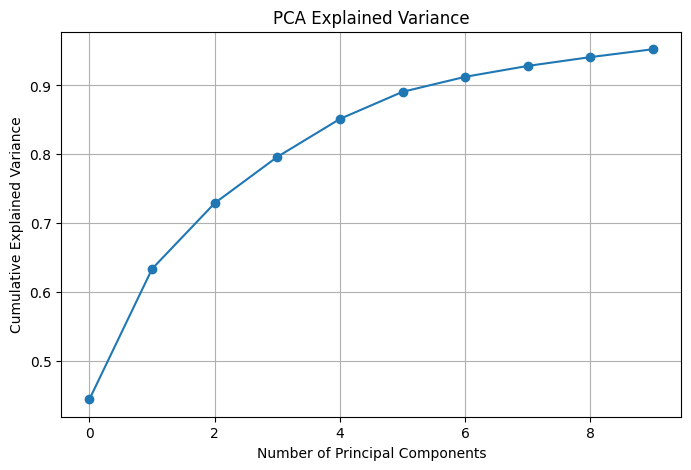

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.grid(True)

plt.show()

In [8]:
logistic_model = LogisticRegression(max_iter=5000)

logistic_model.fit(X_train_pca, y_train)

y_pred_logistic = logistic_model.predict(X_test_pca)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_logistic), 4))

Logistic Regression Accuracy: 0.9737


In [9]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_pca, y_train)

y_pred_knn = knn_model.predict(X_test_pca)

print("KNN Accuracy:",
      round(accuracy_score(y_test, y_pred_knn), 4))

KNN Accuracy: 0.9561


In [10]:
nb_model = GaussianNB()

nb_model.fit(X_train_pca, y_train)

y_pred_nb = nb_model.predict(X_test_pca)

print("Naive Bayes Accuracy:",
      round(accuracy_score(y_test, y_pred_nb), 4))

Naive Bayes Accuracy: 0.9211


In [11]:
models = {
    "Logistic Regression": y_pred_logistic,
    "KNN": y_pred_knn,
    "Naive Bayes": y_pred_nb
}

results = []

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-Score
Logistic Regression    0.9737     0.9859  0.9722    0.9790
                KNN    0.9561     0.9589  0.9722    0.9655
        Naive Bayes    0.9211     0.9315  0.9444    0.9379


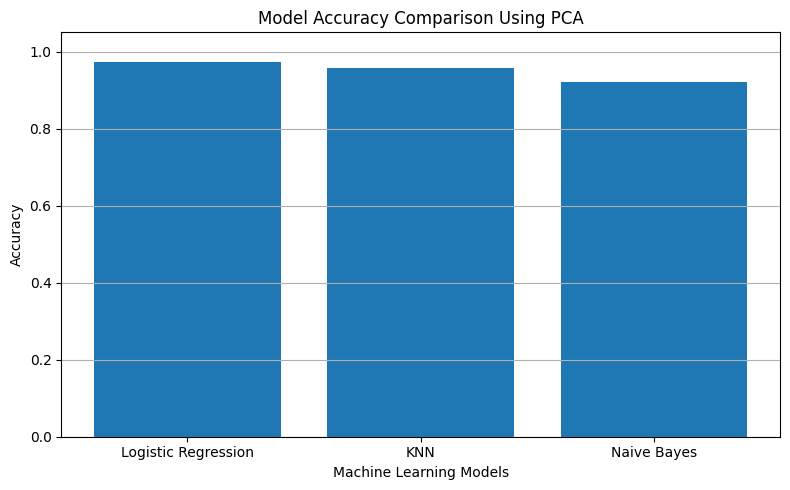

In [12]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Model Accuracy Comparison Using PCA")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.grid(axis="y")
plt.tight_layout()

plt.show()

In [13]:
best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-Score:", round(best_model["F1-Score"], 4))

Best Model: Logistic Regression
Accuracy: 0.9737
Precision: 0.9859
Recall: 0.9722
F1-Score: 0.979


In [14]:
predictions = {
    "Logistic Regression": y_pred_logistic,
    "KNN": y_pred_knn,
    "Naive Bayes": y_pred_nb
}

for model_name, y_pred in predictions.items():
    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=data.target_names,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


KNN
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Naive Bayes
              precision    recall  f1-score   support

   malignant       0.90      0.88      0.89        42
      benign       0.93      0.94      0.94        72

    accuracy                           0.92       114
   macro avg       0.92      0.91      0.91       114
weighted avg       0.92      0.92  

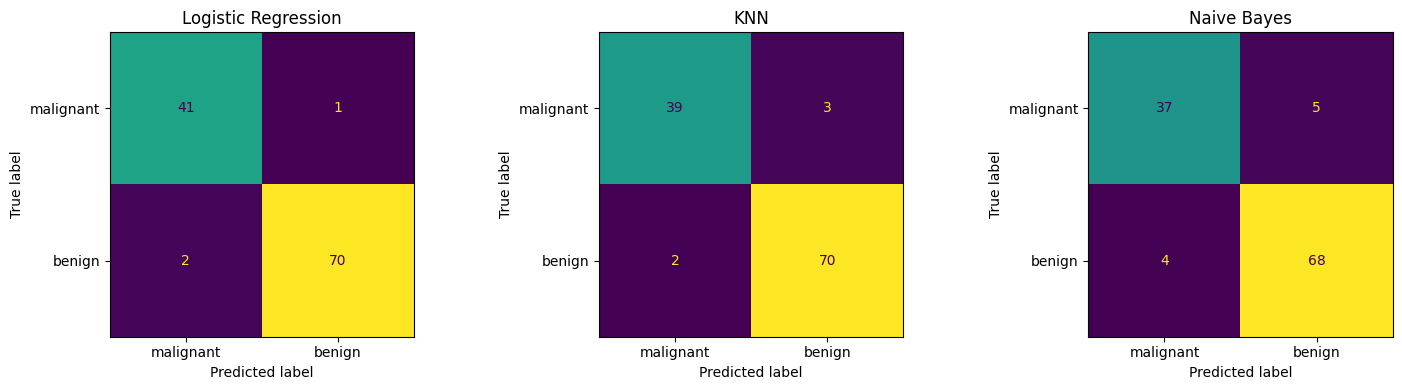

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, y_pred) in zip(
    axes, predictions.items()
):
    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=data.target_names
    )

    display.plot(ax=ax, colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (model_name, y_pred) in zip(
    axes, predictions.items()
):
    cm = confusion_matrix(y_test, y_pred)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=data.target_names
    )

    display.plot(ax=ax, colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()